# Intermediate Demo: SMS Spam / Text Classification with NLP

**Environment:** Amazon SageMaker AI Notebooks (JupyterLab / Jupyter Notebook)  
**Goal:** Build a text classifier that labels an SMS message as **spam** or **ham** (legitimate message).

## Learning outcomes
- Inspect labeled text data and split it into training and test sets.
- Convert text to numeric features with **TF-IDF** (unigrams and bigrams).
- Train and compare **Multinomial Naive Bayes** and **Logistic Regression** classifiers.
- Evaluate precision, recall, F1-score, confusion matrix, and ROC-AUC.
- Inspect useful model features, review mistakes, tune a decision threshold, and save/reload the pipeline.

> **Data note:** `sms_spam_sample.csv` is a synthetic teaching dataset bundled with this notebook. It is designed to make the workflow easy to run without internet access. Metrics reflect this small synthetic dataset, not real-world spam-filter quality. For production or formal benchmarking, replace it with a properly licensed, representative, human-labeled dataset.

## Run in SageMaker
Upload this notebook and `sms_spam_sample.csv` into the same SageMaker Studio/JupyterLab folder, choose a Python kernel, then run cells from top to bottom. No AWS credentials, training job, or endpoint are needed.

If your kernel is missing a dependency, run this in a separate cell and restart the kernel if prompted:
```python
%pip install pandas scikit-learn matplotlib seaborn joblib
```

## 1. Import libraries and set reproducibility options

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score
)
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('scikit-learn version:', sklearn.__version__)

scikit-learn version: 1.8.0


## 2. Load and inspect the labeled SMS dataset
Each row contains a message and its label: `ham` or `spam`.

In [2]:
DATA_PATH = Path('sms_spam_sample.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f'Could not find {DATA_PATH.resolve()}. Upload sms_spam_sample.csv to the same folder as this notebook.'
    )

df = pd.read_csv(DATA_PATH)
required_columns = {'message', 'label'}
if not required_columns.issubset(df.columns):
    raise ValueError(f'Dataset must contain columns: {required_columns}')
df = df.dropna(subset=['message', 'label']).copy()
df['message'] = df['message'].astype(str).str.strip()
df['label'] = df['label'].astype(str).str.lower().str.strip()
df = df[df['label'].isin(['ham', 'spam'])].drop_duplicates(subset=['message']).reset_index(drop=True)

print('Rows:', len(df))
print('Unique labels:', sorted(df['label'].unique()))
display(df.head(10))

Rows: 380
Unique labels: ['ham', 'spam']


,message,label
0,"Hi Maya, are we still meeting at 2 pm near the...",ham
1,Urgent: the reward cannot be sent until you co...,spam
2,Congratulations! You have been selected for a ...,spam
3,"Hi Ravi, are we still meeting at 6:15 near the...",ham
4,Congratulations! You have been selected for a ...,spam
5,"Hi Maya, are we still meeting at noon near the...",ham
6,Get approved for a cash loan in minutes; send ...,spam
7,"Hi Maya, are we still meeting at 2 pm near the...",ham
8,Your account update is ready; verify today to ...,spam
9,Congratulations! You have been selected for a ...,spam


## 3. Explore class balance and message lengths

,message_count
label,
ham,190
spam,190


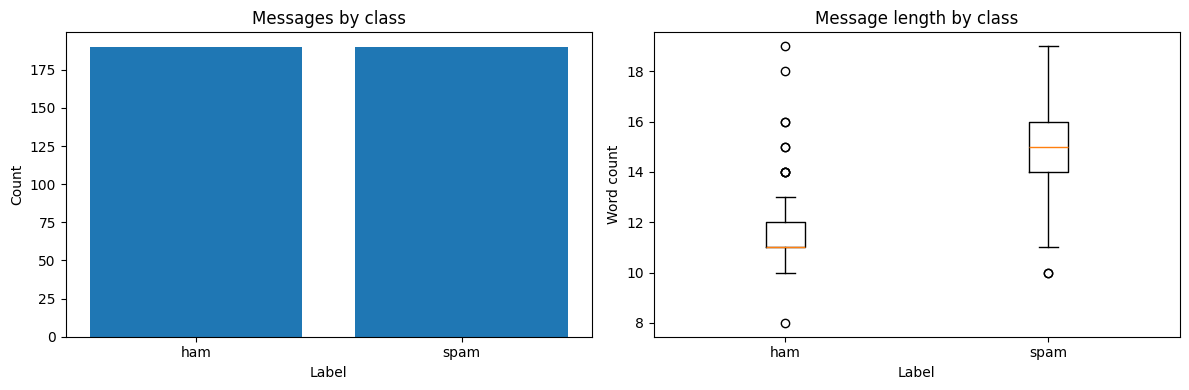

Class proportions:


,proportion
label,
ham,0.5
spam,0.5


In [3]:
class_counts = df['label'].value_counts().reindex(['ham', 'spam'], fill_value=0)
display(class_counts.rename('message_count').to_frame())

df['word_count'] = df['message'].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(class_counts.index, class_counts.values)
axes[0].set_title('Messages by class')
axes[0].set_xlabel('Label')
axes[0].set_ylabel('Count')
axes[1].boxplot([df.loc[df['label'] == 'ham', 'word_count'], df.loc[df['label'] == 'spam', 'word_count']])
axes[1].set_xticks([1, 2], ['ham', 'spam'])
axes[1].set_title('Message length by class')
axes[1].set_xlabel('Label')
axes[1].set_ylabel('Word count')
plt.tight_layout()
plt.show()

print('Class proportions:')
display((class_counts / class_counts.sum()).rename('proportion').to_frame())

## 4. Create a stratified train/test split

We split the raw messages **before fitting TF-IDF**. Because vectorization is inside a scikit-learn `Pipeline`, vocabulary and IDF values are learned from training messages only. This avoids test-data leakage.

In [4]:
label_to_id = {'ham': 0, 'spam': 1}
X = df['message'].astype(str)
y = df['label'].map(label_to_id).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)
print(f'Train records: {len(X_train)} | Test records: {len(X_test)}')
print('Train label proportions:')
display(y_train.map({0:'ham', 1:'spam'}).value_counts(normalize=True).rename('proportion').to_frame())

Train records: 285 | Test records: 95
Train label proportions:


,proportion
label,
spam,0.501754
ham,0.498246


## 5. Build NLP pipelines and compare two classifiers

**TF-IDF** converts text into numeric features. Unigrams capture individual terms; bigrams capture two-word phrases such as `claim prize`. We compare:
- **Multinomial Naive Bayes:** fast probabilistic baseline commonly used for text classification.
- **Logistic Regression:** linear classifier that produces class probabilities and interpretable feature weights.

The preprocessing and classifier are kept together in a `Pipeline` so training and inference use exactly the same transformations.

In [5]:
def make_pipeline(classifier):
    return Pipeline([
        ('tfidf', TfidfVectorizer(
            lowercase=True,
            strip_accents='unicode',
            ngram_range=(1, 2),
            min_df=2,
            max_features=10000,
            sublinear_tf=True
        )),
        ('classifier', classifier)
    ])

models = {
    'Multinomial Naive Bayes': make_pipeline(MultinomialNB(alpha=0.5)),
    'Logistic Regression': make_pipeline(LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=RANDOM_STATE
    ))
}

results = []
for model_name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        'model': model_name,
        'accuracy': accuracy_score(y_test, pred),
        'spam_precision': precision_score(y_test, pred, pos_label=1, zero_division=0),
        'spam_recall': recall_score(y_test, pred, pos_label=1, zero_division=0),
        'spam_f1': f1_score(y_test, pred, pos_label=1, zero_division=0)
    })

results_df = pd.DataFrame(results).set_index('model').sort_values('spam_f1', ascending=False)
display(results_df.round(3))

,accuracy,spam_precision,spam_recall,spam_f1
model,,,,
Logistic Regression,0.958,0.922,1.0,0.959
Multinomial Naive Bayes,0.937,0.887,1.0,0.940


### How to interpret the metrics
- **Precision (spam):** Of messages flagged as spam, how many are actually spam? Low precision means legitimate messages may be blocked.
- **Recall (spam):** Of all spam messages, how many did the model catch? Low recall means more spam reaches the inbox.
- **F1-score:** Harmonic mean of precision and recall.
- **Accuracy:** Overall fraction of correct predictions; it can mislead on imbalanced datasets.

For many spam filters, precision and recall must be balanced according to the cost of false positives versus missed spam.

## 6. Evaluate Logistic Regression in more detail

In [6]:
model = models['Logistic Regression']
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=['HAM', 'SPAM'],
    digits=3,
    zero_division=0
))
print(f'ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}')
print(f'Average precision (PR-AUC summary): {average_precision_score(y_test, y_prob):.3f}')

              precision    recall  f1-score   support

         HAM      1.000     0.917     0.957        48
        SPAM      0.922     1.000     0.959        47

    accuracy                          0.958        95
   macro avg      0.961     0.958     0.958        95
weighted avg      0.961     0.958     0.958        95

ROC-AUC: 0.999
Average precision (PR-AUC summary): 0.999


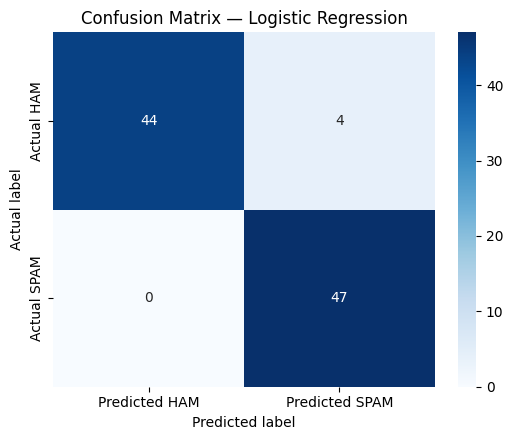

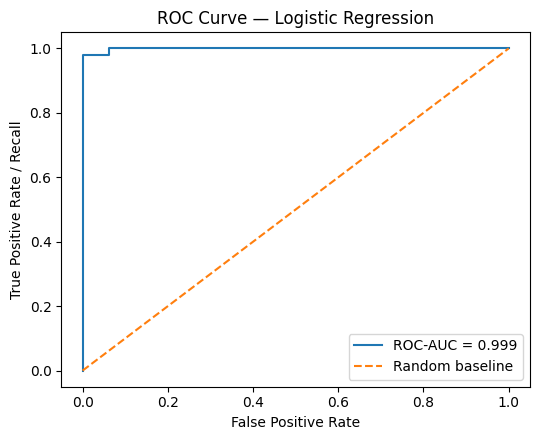

In [7]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted HAM', 'Predicted SPAM'], yticklabels=['Actual HAM', 'Actual SPAM'])
plt.title('Confusion Matrix — Logistic Regression')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y_test, y_prob):.3f}")
plt.plot([0, 1], [0, 1], linestyle='--', label='Random baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate / Recall')
plt.title('ROC Curve — Logistic Regression')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Inspect words and phrases learned by Logistic Regression

Positive coefficients push a prediction toward **SPAM**; negative coefficients push toward **HAM**. These are model associations, not guaranteed rules.

Terms most associated with SPAM:


,term,weight
0,your,1.364
1,claim,1.126
2,example,0.988
3,example test,0.988
4,test,0.988
5,selected,0.797
6,for,0.750
7,selected for,0.719
8,test before,0.702
9,you have,0.702


Terms most associated with HAM:


,term,weight
0,the,-1.321
1,we,-1.105
2,meeting,-1.095
3,are,-1.080
4,near the,-1.016
5,meeting at,-1.016
6,still meeting,-1.016
7,still,-1.016
8,we still,-1.016
9,are we,-1.016


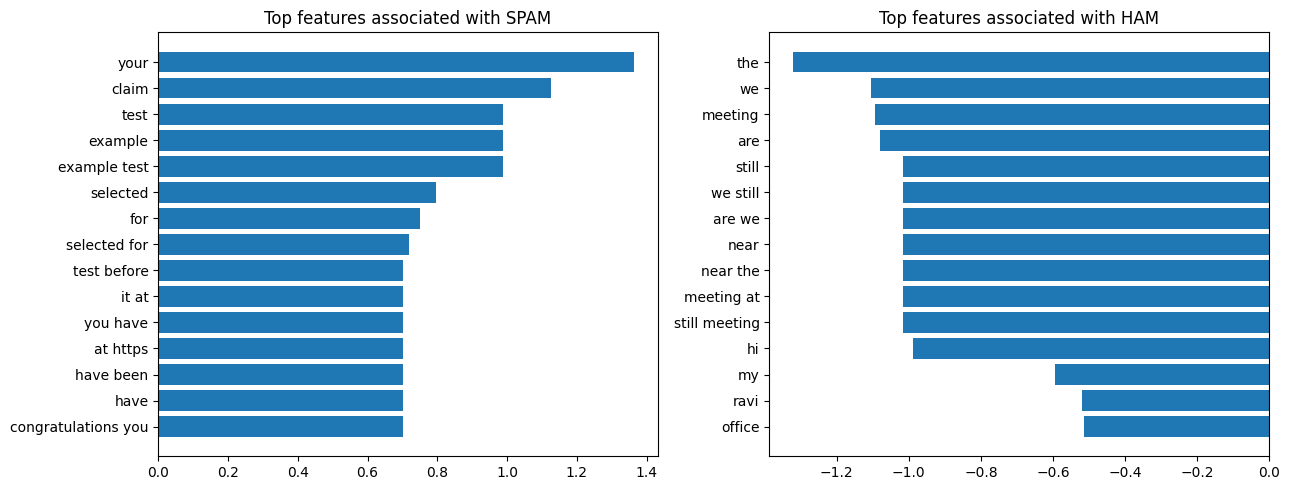

In [8]:
tfidf = model.named_steps['tfidf']
classifier = model.named_steps['classifier']
feature_names = tfidf.get_feature_names_out()
coefficients = classifier.coef_[0]

terms = pd.DataFrame({'term': feature_names, 'weight': coefficients})
top_spam_terms = terms.sort_values('weight', ascending=False).head(15)
top_ham_terms = terms.sort_values('weight', ascending=True).head(15)
print('Terms most associated with SPAM:')
display(top_spam_terms.reset_index(drop=True).round(3))
print('Terms most associated with HAM:')
display(top_ham_terms.reset_index(drop=True).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
spam_plot = top_spam_terms.sort_values('weight')
axes[0].barh(spam_plot['term'], spam_plot['weight'])
axes[0].set_title('Top features associated with SPAM')
ham_plot = top_ham_terms.sort_values('weight', ascending=False)
axes[1].barh(ham_plot['term'], ham_plot['weight'])
axes[1].set_title('Top features associated with HAM')
plt.tight_layout()
plt.show()

## 8. Error analysis: inspect messages the model got wrong

In [9]:
error_analysis = pd.DataFrame({
    'message': X_test.to_numpy(),
    'actual': y_test.map({0:'ham', 1:'spam'}).to_numpy(),
    'predicted': pd.Series(y_pred).map({0:'ham', 1:'spam'}).to_numpy(),
    'spam_probability': y_prob
})
errors = error_analysis[error_analysis['actual'] != error_analysis['predicted']].copy()
print(f'Incorrect predictions: {len(errors)} out of {len(error_analysis)} test examples')
if errors.empty:
    print('No errors on this particular synthetic test split. Use the custom examples below to discuss edge cases.')
else:
    display(errors.sort_values('spam_probability').head(10).round({'spam_probability': 3}))

Incorrect predictions: 4 out of 95 test examples


,message,actual,predicted,spam_probability
60,Could you send me the free offer details for t...,ham,spam,0.531
30,Your parcel is at reception; the delivery fee ...,ham,spam,0.600
6,Your account password will expire soon; update...,ham,spam,0.610
15,"The website says claim your ticket, but this i...",ham,spam,0.638


## 9. Adjust the spam decision threshold

`predict()` normally uses a threshold of 0.50 for the positive class. Lowering the threshold usually catches more spam (higher recall) but can flag more legitimate messages (lower precision). Choose the operating point based on business costs, not accuracy alone.

In [10]:
threshold = 0.35
y_pred_threshold = (y_prob >= threshold).astype(int)
print(f'Custom threshold: {threshold:.2f}')
print('Default 0.50 threshold:')
print(f"  spam precision={precision_score(y_test, y_pred, pos_label=1, zero_division=0):.3f}, spam recall={recall_score(y_test, y_pred, pos_label=1, zero_division=0):.3f}")
print(f'Threshold {threshold:.2f}:')
print(f"  spam precision={precision_score(y_test, y_pred_threshold, pos_label=1, zero_division=0):.3f}, spam recall={recall_score(y_test, y_pred_threshold, pos_label=1, zero_division=0):.3f}")
print('Interpretation: lowering the threshold can increase spam recall, but always verify the precision/false-positive trade-off on representative data.')

Custom threshold: 0.35
Default 0.50 threshold:
  spam precision=0.922, spam recall=1.000
Threshold 0.35:
  spam precision=0.887, spam recall=1.000
Interpretation: lowering the threshold can increase spam recall, but always verify the precision/false-positive trade-off on representative data.


## 10. Try the classifier on new messages

In [11]:
new_messages = [
    'Congratulations, you won a free shopping voucher. Claim it now at rewards.example.test',
    'Are we still meeting at the library at 4:30 this afternoon?',
    'Your account is restricted. Verify your details immediately to unlock the reward.',
    'I have shared the project notes in the team folder. Please review before our meeting.',
    'You have a package waiting; pay the small delivery fee using this link.'
]

new_probabilities = model.predict_proba(new_messages)[:, 1]
new_predictions = (new_probabilities >= 0.50).astype(int)
prediction_results = pd.DataFrame({
    'message': new_messages,
    'predicted_label': pd.Series(new_predictions).map({0:'HAM', 1:'SPAM'}),
    'spam_probability': new_probabilities.round(3)
})
display(prediction_results)

,message,predicted_label,spam_probability
0,"Congratulations, you won a free shopping vouch...",SPAM,0.870
1,Are we still meeting at the library at 4:30 th...,HAM,0.131
2,Your account is restricted. Verify your detail...,SPAM,0.756
3,I have shared the project notes in the team fo...,HAM,0.356
4,You have a package waiting; pay the small deli...,SPAM,0.663


## 11. Save and reload the complete pipeline

In [12]:
MODEL_PATH = Path('sms_spam_logistic_regression_pipeline.joblib')
model_artifact = {
    'pipeline': model,
    'id_to_label': {0: 'ham', 1: 'spam'},
    'decision_threshold': 0.50,
    'notes': 'Trained on a small synthetic teaching dataset; not production validated.'
}
joblib.dump(model_artifact, MODEL_PATH)
print('Saved to:', MODEL_PATH.resolve())

loaded_artifact = joblib.load(MODEL_PATH)
loaded_model = loaded_artifact['pipeline']
check_message = 'You have won a prize. Claim your reward today.'
check_probability = loaded_model.predict_proba([check_message])[0, 1]
check_label_id = int(check_probability >= loaded_artifact['decision_threshold'])
print('Test message:', check_message)
print('Predicted label:', loaded_artifact['id_to_label'][check_label_id].upper())
print(f'Spam probability: {check_probability:.3f}')

Saved to: /mnt/data/sagemaker_spam_text_classification/sms_spam_logistic_regression_pipeline.joblib
Test message: You have won a prize. Claim your reward today.
Predicted label: SPAM
Spam probability: 0.817


## 12. Key takeaways, limitations, and student exercises

### Key takeaways
- Raw text must be converted to numeric representations before a classical ML classifier can train on it.
- TF-IDF captures token importance; bigrams can encode short phrases.
- A `Pipeline` keeps vectorization and prediction consistent and helps prevent leakage.
- Use precision, recall, F1, confusion matrix and threshold trade-offs—not accuracy alone.
- Feature weights and error analysis help explain model behaviour.

### Limitations
- This bundled corpus is synthetic and contains teaching patterns. Its scores are not a realistic estimate of production performance.
- Real messages may contain slang, misspellings, multiple languages, URLs, adversarial wording and changing spam campaigns.
- Avoid placing personal or sensitive messages into notebooks without appropriate authorization and data protection controls.
- `joblib` model files should only be loaded from trusted sources.

### Student exercises
1. Change `ngram_range=(1, 2)` to `(1, 1)`. How do metrics and learned terms change?
2. Try `min_df=3` or `max_features=3000`. What changes in model size and performance?
3. Compare thresholds `0.25`, `0.50`, and `0.75`. Which gives the best spam recall? What happens to precision?
4. Add 10 correctly labeled examples containing ambiguous language (for example, a legitimate message containing “free” or “urgent”) and rerun the evaluation. Explain errors.
5. Propose a validation plan using a licensed real-world dataset and a time-based test set to measure performance on future messages.

**End of demo.**